5. Every transformation and every selection is fitted on the training actors of each LOSO fold, and never on all 
videos. In this section C is fixed to the value chosen most often in 4.6; state in the report what this 
simplification may cost. The features are all those of Section 3.

C is fixed at 1, the value chosen in 16 of the 20 folds of 4.6, which used all the features of Section 3. This may cost us in two ways. First, the pipelines with PCA or feature selection feed the SVM a different input (fewer or transformed features), and C = 1 was not tuned for it, so these pipelines may be slightly underestimated relative to the baseline, which uses the C that was tuned for it. Second, the most frequent value was read off all the development actors, so the LOSO scores of this section are marginally optimistic.

Question 5.1 Apply principal component analysis (PCA) to the standardised features of all development videos, for 
exploration only. Plot the cumulative explained variance and report the number of components that explain 75 % and 95 % of the variance. Which measures dominate the first two components? Plot the videos on the first two components, coloured by emotion.

Initial total features:['M1_mean', 'M1_std', 'M1_range', 'M1_v', 'M1_E', 'M2_mean', 'M2_std', 'M2_range', 'M2_v', 'M2_E', 'M3_mean', 'M3_std', 'M3_range', 'M3_v', 'M3_E', 'M4_mean', 'M4_std', 'M4_range', 'M4_v', 'M4_E', 'M5_mean', 'M5_std', 'M5_range', 'M5_v', 'M5_E', 'M6_mean', 'M6_std', 'M6_range', 'M6_v', 'M6_E', 'M7_mean', 'M7_std', 'M7_range', 'M7_v', 'M7_E', 'M8_mean', 'M8_std', 'M8_range', 'M8_v', 'M8_E', 'M9_mean', 'M9_std', 'M9_range', 'M9_v', 'M9_E', 'M10_mean', 'M10_std', 'M10_range', 'M10_v', 'M10_E', 'M11_mean', 'M11_std', 'M11_range', 'M11_v', 'M11_E']
Cumulative Explained Variance: [0.35824443 0.48238188 0.55162382 0.602934   0.64529044 0.68383805
 0.71372853 0.74164394 0.76600584 0.78983118 0.8117431  0.83199225
 0.84833311 0.86278187 0.87671897 0.88943037 0.900921   0.91038139
 0.91932735 0.92710434 0.93437174 0.94047713 0.94629153 0.95153849
 0.95625645 0.9605816  0.96453213 0.96795517 0.97096216 0.97387124
 0.97646721 0.97894269 0.98105768 0.98303803 0.98474948 0.986

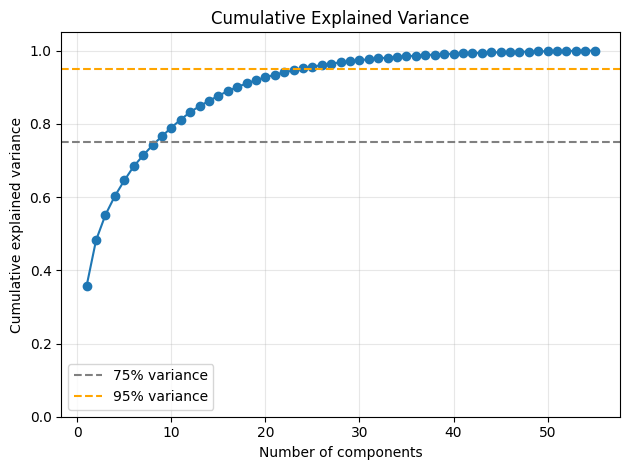

Number of components: 55
Number of components for 75% variance: 9
Number of components for 95% variance: 24

--- Dominant Measures for PC1 ---
measure
M1     0.151265
M2     0.148551
M8     0.148230
M10    0.148040
M3     0.147317
M7     0.147260
M9     0.108019
M6     0.098009
M11    0.085254
M4     0.082461
M5     0.067646
Name: PC1, dtype: float64

--- Dominant Measures for PC2 ---
measure
M4     0.220353
M5     0.213342
M1     0.152493
M9     0.127529
M11    0.117871
M6     0.112548
M10    0.096578
M2     0.089104
M3     0.063419
M7     0.061212
M8     0.020000
Name: PC2, dtype: float64


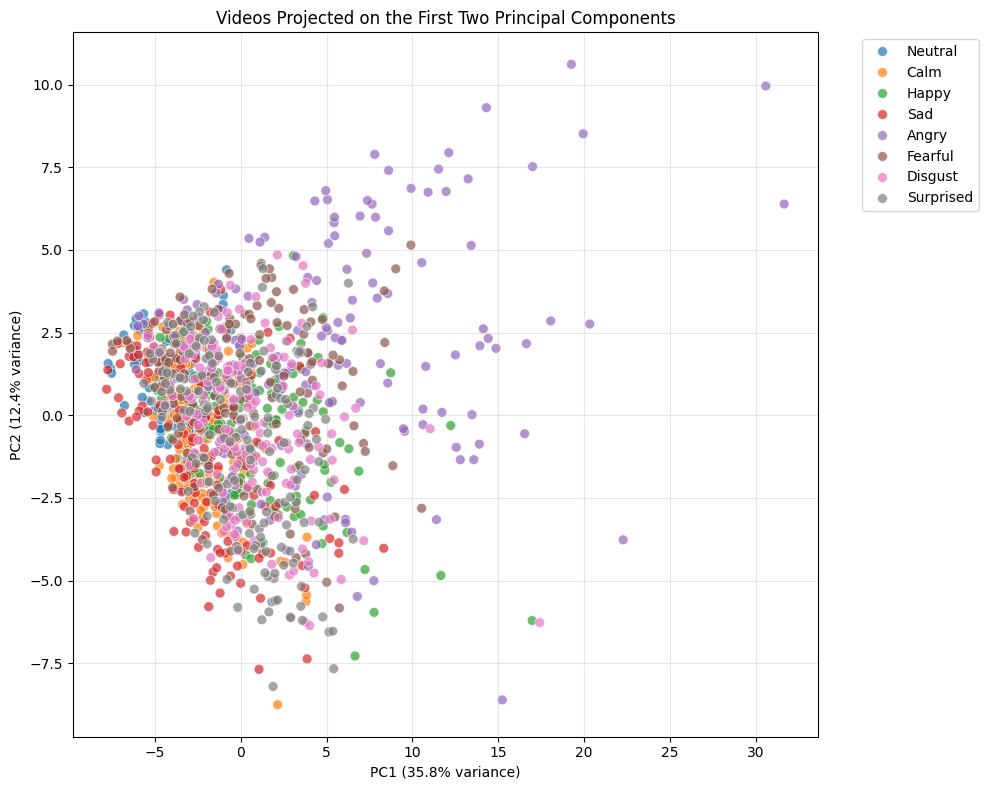

In [1]:
import numpy as np
from sklearn.decomposition import PCA
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

df_all = pd.read_parquet("new_3.2_video_measurements.gzip")
testIndex = pd.read_parquet("testIndex.gzip")
dev_data = df_all[
    ~df_all["video"].isin(testIndex["video"])
].copy()

# Extract actor ID from the video filename
dev_data["actor"] = (
    dev_data["video"]
    .str.replace(".csv", "", regex=False)
    .str.split("-")
    .str[-1]
)

feature_cols = [
    c for c in dev_data.select_dtypes(include="number").columns
    if c != "frame"
]
print(f"Initial total features:{feature_cols}")
X = StandardScaler().fit_transform(dev_data[feature_cols])

pca = PCA()
pca.fit(X)
cumulative_explained_variance = np.cumsum(pca.explained_variance_ratio_)
print(f"Cumulative Explained Variance: {cumulative_explained_variance}")

components = np.arange(1, pca.n_components_ + 1)
plt.plot(components, cumulative_explained_variance, marker="o")
plt.axhline(y=0.75, color="gray", linestyle="--", label="75% variance")
plt.axhline(y=0.95, color="orange", linestyle="--", label="95% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative Explained Variance")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Number of components: {pca.n_components_}")

import seaborn as sns

# 1. Report the number of components for 75% and 95% variance
n_comp_75 = np.argmax(cumulative_explained_variance >= 0.75) + 1
n_comp_95 = np.argmax(cumulative_explained_variance >= 0.95) + 1
print(f"Number of components for 75% variance: {n_comp_75}")
print(f"Number of components for 95% variance: {n_comp_95}")

# 2. Determine which measures dominate the first two components
feature_names = feature_cols
loadings_df = pd.DataFrame(
    pca.components_[:2, :], 
    columns=feature_names, 
    index=['PC1', 'PC2']
).T

# Add the measure group column
loadings_df['measure'] = [col.split('_')[0] if '_' in col else col for col in feature_names]

# Take absolute values only on the numeric PC columns, then group by measure
numeric_loadings = loadings_df[['PC1', 'PC2']].abs()
numeric_loadings['measure'] = loadings_df['measure']
measure_importance = numeric_loadings.groupby('measure').mean()

print("\n--- Dominant Measures for PC1 ---")
print(measure_importance['PC1'].sort_values(ascending=False))

print("\n--- Dominant Measures for PC2 ---")
print(measure_importance['PC2'].sort_values(ascending=False))

# 3. Plot the videos on the first two components, coloured by emotion
X_pca = pca.transform(X)
plot_df = pd.DataFrame(X_pca[:, :2], columns=['PC1', 'PC2'])
plot_df['emotion'] = dev_data['emotion'].values

plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=plot_df, 
    x='PC1', 
    y='PC2', 
    hue='emotion', 
    palette='tab10', 
    alpha=0.7, 
    s=50
)
plt.title("Videos Projected on the First Two Principal Components")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The number of principal components required to explain 75% of the variance is 9, while the number required to explain 95% is 24.
After the features were grouped up based on their measure, and their absolute PC1 and PC2 weights were averaged (mean), we found that the dominant measures for PC1 were, from most dominant to least, M1, M2,M8, M10, M3, M7, M9, M6, M11, M4 and M5, while the dominant measures for PC2 were M4, M5, M1, M9, M11, M6, M10, M2, M3, M7 and M8.

Question 5.2 Under LOSO, evaluate the pipelines StandardScaler → PCA → SVC keeping 75 % and 95 % of the 
variance. Compare with all the features. Does compressing the representation help the classifier? 
Why?

In [2]:
from sklearn.decomposition import PCA
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

X = dev_data[feature_cols]
y = dev_data["emotion"]
groups = dev_data["actor"]

logo = LeaveOneGroupOut()

pca_variants = {
    "75% Variance (9 PCs)": n_comp_75,
    "95% Variance (24 PCs)": n_comp_95,
}

results = {}

for name, n_components in pca_variants.items():
    # Build pipeline: Standardize -> Apply PCA -> Train SVC (fixed C=1)
    pipeline = Pipeline(
        [
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=n_components, random_state=42)),
            ("svc", SVC(C=1, kernel="rbf", random_state=42)),
        ]
    )

    fold_accuracies = []

    # Iterate over LOSO folds
    for train_idx, test_idx in logo.split(X, y, groups=groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        # Fit ONLY on training actors, evaluate on left-out test actor
        pipeline.fit(X_train, y_train)
        score = pipeline.score(X_test, y_test)
        fold_accuracies.append(score)

    mean_acc = np.mean(fold_accuracies)
    std_acc = np.std(fold_accuracies)
    results[name] = (mean_acc, std_acc)

    print(f"=== {name} ===")
    print(f"Mean LOSO Accuracy: {mean_acc * 100:.2f}% (± {std_acc * 100:.2f}%)\n")

# ==========================================
# 3. Summary Table
# ==========================================
df_results = pd.DataFrame(
    results, index=["Mean Accuracy", "Std Dev"]
).T.style.format("{:.4f}")

=== 75% Variance (9 PCs) ===
Mean LOSO Accuracy: 53.25% (± 11.12%)

=== 95% Variance (24 PCs) ===
Mean LOSO Accuracy: 57.67% (± 10.97%)



The difference between the mean accuracy of 75% variance and 95% is of just 4.42% while their standard deviations are 11.06% and 10.97%. Since their standard deviation is larger than the difference in mean,the discrepancy between the performance of 75% and 95% variance is considered not statistically significant.

Since compressing the representation does not meaningfully hurt performance, it is preferred, as it reduces noise and risk of overfitting.

Question 5.3
Univariate selection: SelectKBest with the ANOVA F-statistic (f_classif) inside the pipeline, with K = 5, 10 and 15. Report the LOSO macro F1.

In [ ]:
from sklearn.feature_selection import SelectKBest,f_classif
from sklearn.metrics import f1_score

X = dev_data[feature_cols]
y = dev_data["emotion"]
groups = dev_data["actor"]

logo = LeaveOneGroupOut()
k_dic = {"K=5" : 5,"K=10" : 10,"K=15" : 15}
results_53 = {}

for name, k in k_dic.items():
    pipeline = Pipeline(
            [
                ("scaler", StandardScaler()),
                ("select", SelectKBest(f_classif, k=k)),
                ("svc", SVC(C=1, kernel="rbf", random_state=42)),
            ]
        )

    fold_f1 = []
    for train_idx, test_idx in logo.split(X, y, groups=groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        # Fit ONLY on training actors, evaluate on left-out test actor
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)
        fold_f1.append(f1_score(y_test, y_pred, average="macro"))
        
    results_53[name] = [np.mean(fold_f1), np.std(fold_f1)]
    
    print(f"LOSO MACRO F1 FOR {name}: {np.mean(fold_f1) * 100:.2f}% (± {np.std(fold_f1) * 100:.2f}%)\n")

# ==========================================
# 3. Summary Table
# ==========================================
df_results_53 = pd.DataFrame(
    results_53, index=["Mean Macro F1", "Std Dev"]
).T.style.format("{:.4f}")    

df_results_53
    

LOSO MACRO F1 FOR K=5: 35.95% (± 10.26%)

LOSO MACRO F1 FOR K=10: 41.61% (± 11.77%)

LOSO MACRO F1 FOR K=15: 45.03% (± 9.70%)



,Mean Macro Accuracy,Std Dev
K=5,0.3595,0.1026
K=10,0.4161,0.1177
K=15,0.4503,0.0970


Question 5.4 
Minimum redundancy, maximum relevance (mRMR) [6]: select K = 5, 10 and 15 features with mrmr_classif from the mrmr_selection package (pip install mrmr_selection), on the training actors of each LOSO fold. With its default arguments, the package measures the relevance of a feature by its F-statistic and its redundancy by its mean absolute Pearson correlation with the features already selected, and selects at each step the feature that maximises the quotient of the two, a variant proposed for continuous features in [7]. The function is not a scikit-learn transformer: the selection is performed explicitly within each fold, or wrapped in a transformer. Compare with 5.3.

In [ ]:
import sklearn
%pip install -U scikit-learn



Note: you may need to restart the kernel to use updated packages.


ImportError: cannot import name 'Tags' from 'sklearn.utils' (/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/__init__.py)